# Flipkart Smartphone Price and Specification Analysis

## 1. Import libraries

In [1]:
import requests
import re
import time
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Configure the request and search pages

In [2]:
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/137.0.0.0 Safari/537.36",
    "Accept-Language": "en-US,en;q=0.9",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8",
    "Referer": "https://www.google.com/"
}

# Search results for 5G smartphones. Scrape at least 10 pages to increase the sample size.
base_url = "https://www.flipkart.com/search?q=mobile+5g&sid=tyy%2C4io"
number_of_pages = 10

## 3. Web scraping

In [3]:
Brand = []
Model = []
Price = []
Color = []
RAM = []
ROM = []
Battery = []
Display = []
Reviews = []

for page_no in range(1, number_of_pages + 1):
    url = base_url + "&page=" + str(page_no)
    response = requests.get(url, headers=headers, timeout=20)
    print("Page:", page_no, "| HTTP status:", response.status_code, "| URL:", url)

    soup = BeautifulSoup(response.text, "html.parser")

    # Title selectors based on the provided example, followed by alternative selectors.
    title_nodes = soup.select("div.RG5Slk")
    if not title_nodes:
        title_nodes = soup.select("div.KzDlHZ")
    if not title_nodes:
        title_nodes = soup.select("a[title]")

    # Price and specification selectors based on the provided example and common alternatives.
    price_nodes = soup.select("div.hZ3P6w.DeU9vF")
    if not price_nodes:
        price_nodes = soup.select("div.Nx9bqj")
    feature_nodes = soup.select("div.CMXw7N")
    if not feature_nodes:
        feature_nodes = soup.select("li._21Ahn-")

    print("Product title elements found:", len(title_nodes))

    # Walk upward from each title until a likely product card containing a price is found.
    for title_node in title_nodes:
        title_text = title_node.get_text(" ", strip=True)
        if not title_text or len(title_text) < 4:
            continue

        card = title_node
        for level in range(5):
            if card.parent is None:
                break
            card = card.parent
            card_text = card.get_text(" ", strip=True)
            card_price = card.select_one("div.hZ3P6w.DeU9vF, div.Nx9bqj, div._30jeq3")
            if card_price is not None and len(card_text) < 1800:
                break

        card_text = card.get_text(" ", strip=True)
        price_node = card.select_one("div.hZ3P6w.DeU9vF, div.Nx9bqj, div._30jeq3")
        if price_node is None:
            # Last-resort price extraction from the product-card text.
            price_match = re.search(r"₹\s?[\d,]+", card_text)
            price_text = price_match.group(0) if price_match else np.nan
        else:
            price_text = price_node.get_text(" ", strip=True)

        feature_texts = [node.get_text(" ", strip=True) for node in card.select("div.CMXw7N, li._21Ahn-")]
        features_text = " | ".join(feature_texts)
        if not features_text:
            features_text = card_text

        price_match = re.search(r"[\d,]+", str(price_text))
        price_value = price_match.group(0) if price_match else np.nan

        ram_match = re.search(r"(\d+)\s*GB\s*RAM", features_text, flags=re.I)
        rom_match = re.search(r"(\d+)\s*GB\s*(?:ROM|Storage)", features_text, flags=re.I)
        battery_match = re.search(r"(\d{3,5})\s*mAh", features_text, flags=re.I)
        display_match = re.search(r"(\d+(?:\.\d+)?)\s*cm", features_text, flags=re.I)
        reviews_match = re.search(r"([\d,]+)\s*(?:Ratings|Reviews)", card_text, flags=re.I)

        # Brand is approximated from the first word of the listing title.
        title_clean = re.sub(r"\s+", " ", title_text).strip()
        brand_value = title_clean.split(" ")[0]
        model_value = title_clean[len(brand_value):].strip(" -") or title_clean

        Brand.append(brand_value)
        Model.append(model_value)
        Price.append(price_value)
        color_match = re.search(r"\(([^,()]+),", title_clean)
        Color.append(color_match.group(1).strip() if color_match else np.nan)
        RAM.append(ram_match.group(1) if ram_match else np.nan)
        ROM.append(rom_match.group(1) if rom_match else np.nan)
        Battery.append(battery_match.group(1) if battery_match else np.nan)
        Display.append(display_match.group(1) if display_match else np.nan)
        Reviews.append(reviews_match.group(1).replace(",", "") if reviews_match else np.nan)

    time.sleep(2)

print("Total product records collected:", len(Brand))

Page: 1 | HTTP status: 200 | URL: https://www.flipkart.com/search?q=mobile+5g&sid=tyy%2C4io&page=1
Product title elements found: 24
Page: 2 | HTTP status: 200 | URL: https://www.flipkart.com/search?q=mobile+5g&sid=tyy%2C4io&page=2
Product title elements found: 24
Page: 3 | HTTP status: 200 | URL: https://www.flipkart.com/search?q=mobile+5g&sid=tyy%2C4io&page=3
Product title elements found: 24
Page: 4 | HTTP status: 200 | URL: https://www.flipkart.com/search?q=mobile+5g&sid=tyy%2C4io&page=4
Product title elements found: 24
Page: 5 | HTTP status: 200 | URL: https://www.flipkart.com/search?q=mobile+5g&sid=tyy%2C4io&page=5
Product title elements found: 24
Page: 6 | HTTP status: 200 | URL: https://www.flipkart.com/search?q=mobile+5g&sid=tyy%2C4io&page=6
Product title elements found: 24
Page: 7 | HTTP status: 200 | URL: https://www.flipkart.com/search?q=mobile+5g&sid=tyy%2C4io&page=7
Product title elements found: 24
Page: 8 | HTTP status: 200 | URL: https://www.flipkart.com/search?q=mobile+5

## 4. Create the raw DataFrame `df` and save the scraped data

In [4]:
data = {
    "Brand": Brand,
    "Model": Model,
    "Price": Price,
    "Color": Color,
    "RAM_GB": RAM,
    "Storage_GB": ROM,
    "Battery_mAh": Battery,
    "Display_cm": Display,
    "Reviews": Reviews
}

df = pd.DataFrame(data)
print("Raw dataset shape:", df.shape)
df.head(10)

Raw dataset shape: (240, 9)


,Brand,Model,Price,Color,RAM_GB,Storage_GB,Battery_mAh,Display_cm,Reviews
0,Mivi,"One 5G (Green, 128 GB)","13,999",Green,6,128,6000,17.14,NaN
1,Samsung,"Galaxy S25 5G Snapdragon (Silver Shadow, 128 GB)","55,299",Silver Shadow,12,128,4000,15.75,6830
2,HMD,"Vibe2Pro 5G with Sarvam AI (Silver Mist, 128 GB)","16,999",Silver Mist,8,128,6000,17.22,NaN
3,Apple,"iPhone 17 (Black, 256 GB)","86,999",Black,NaN,256,NaN,16.0,28706
4,OPPO,"K14 Plus 5G (Solar Orange, 128 GB)","29,999",Solar Orange,6,128,8000,17.22,166
5,Mivi,"One 5G (Green, 128 GB)","14,999",Green,8,128,6000,17.14,NaN
6,vivo,"T5x 5G (Cosmic Green, 128 GB)","27,749",Cosmic Green,6,128,7200,17.17,22608
7,Samsung,"Galaxy A36 5G (Awesome Lavender, 128 GB)","25,999",Awesome Lavender,8,128,5000,17.02,6250
8,Google,"Pixel 10a (Fog, 256 GB)","47,999",Fog,8,256,5100,16.0,3244
9,Ai+,"Nova 2 Neo 5G (Blue, 128 GB)","14,499",Blue,4,128,6000,17.13,2452


In [5]:
df.to_csv("flipkart_smartphone_raw.csv", index=False, encoding="utf-8-sig")
print("Saved: flipkart_smartphone_raw.csv")

Saved: flipkart_smartphone_raw.csv


### Scraping validation

In [6]:
if df.empty:
    print("No records were scraped. Check Flipkart's response and update the selectors before proceeding.")
else:
    print("Unique product titles:", df["Model"].nunique())
    print("Duplicate title rows:", df["Model"].duplicated().sum())
    print("Columns:", df.columns.tolist())

Unique product titles: 129
Duplicate title rows: 111
Columns: ['Brand', 'Model', 'Price', 'Color', 'RAM_GB', 'Storage_GB', 'Battery_mAh', 'Display_cm', 'Reviews']


## 5. Data understanding before cleaning

In [7]:
print("Rows and columns:", df.shape)
print("\nColumn data types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.head()

Rows and columns: (240, 9)

Column data types:
Brand          object
Model          object
Price          object
Color          object
RAM_GB         object
Storage_GB     object
Battery_mAh    object
Display_cm     object
Reviews        object
dtype: object

Missing values:
Brand           0
Model           0
Price           0
Color           3
RAM_GB          6
Storage_GB      0
Battery_mAh     6
Display_cm      0
Reviews        21
dtype: int64

Duplicate rows: 103


,Brand,Model,Price,Color,RAM_GB,Storage_GB,Battery_mAh,Display_cm,Reviews
0,Mivi,"One 5G (Green, 128 GB)","13,999",Green,6,128,6000,17.14,NaN
1,Samsung,"Galaxy S25 5G Snapdragon (Silver Shadow, 128 GB)","55,299",Silver Shadow,12,128,4000,15.75,6830
2,HMD,"Vibe2Pro 5G with Sarvam AI (Silver Mist, 128 GB)","16,999",Silver Mist,8,128,6000,17.22,NaN
3,Apple,"iPhone 17 (Black, 256 GB)","86,999",Black,NaN,256,NaN,16.0,28706
4,OPPO,"K14 Plus 5G (Solar Orange, 128 GB)","29,999",Solar Orange,6,128,8000,17.22,166


## 6. Data cleaning

In [8]:
clean_df = df.copy()

# Remove leading/trailing spaces and standardize text columns.
for column in ["Brand", "Model", "Color"]:
    clean_df[column] = clean_df[column].astype("string").str.strip()
    clean_df[column] = clean_df[column].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# Extract color from text inside parentheses when the scraper has not already captured it.
color_from_model = clean_df["Model"].astype("string").str.extract(r"\(([^,()]+),", expand=False).str.strip()
clean_df["Color"] = clean_df["Color"].fillna(color_from_model)

# Convert numeric fields. Price values may contain commas or currency symbols.
clean_df["Price"] = pd.to_numeric(
    clean_df["Price"].astype("string").str.replace(r"[^0-9.]", "", regex=True),
    errors="coerce"
)

for column in ["RAM_GB", "Storage_GB", "Battery_mAh", "Display_cm", "Reviews"]:
    clean_df[column] = pd.to_numeric(clean_df[column], errors="coerce")

# Remove rows without a usable product title or positive price.
clean_df = clean_df.dropna(subset=["Model", "Price"])
clean_df = clean_df[clean_df["Price"] > 0]

# Remove duplicate listings using brand, model, and price, retaining the first occurrence.
clean_df = clean_df.drop_duplicates(subset=["Brand", "Model", "Price"], keep="first")

# Use nullable integer types for whole-number specifications.
for column in ["RAM_GB", "Storage_GB", "Battery_mAh", "Reviews"]:
    clean_df[column] = clean_df[column].round().astype("Int64")

# Standardize brand capitalization without changing model text.
clean_df["Brand"] = clean_df["Brand"].str.strip().str.title()

clean_df = clean_df.reset_index(drop=True)

print("Raw shape:", df.shape)
print("Cleaned shape:", clean_df.shape)
print("Rows removed:", len(df) - len(clean_df))
clean_df.head(10)

Raw shape: (240, 9)
Cleaned shape: (137, 9)
Rows removed: 103


,Brand,Model,Price,Color,RAM_GB,Storage_GB,Battery_mAh,Display_cm,Reviews
0,Mivi,"One 5G (Green, 128 GB)",13999,Green,6,128,6000,17.14,<NA>
1,Samsung,"Galaxy S25 5G Snapdragon (Silver Shadow, 128 GB)",55299,Silver Shadow,12,128,4000,15.75,6830
2,Hmd,"Vibe2Pro 5G with Sarvam AI (Silver Mist, 128 GB)",16999,Silver Mist,8,128,6000,17.22,<NA>
3,Apple,"iPhone 17 (Black, 256 GB)",86999,Black,<NA>,256,<NA>,16.00,28706
4,Oppo,"K14 Plus 5G (Solar Orange, 128 GB)",29999,Solar Orange,6,128,8000,17.22,166
5,Mivi,"One 5G (Green, 128 GB)",14999,Green,8,128,6000,17.14,<NA>
6,Vivo,"T5x 5G (Cosmic Green, 128 GB)",27749,Cosmic Green,6,128,7200,17.17,22608
7,Samsung,"Galaxy A36 5G (Awesome Lavender, 128 GB)",25999,Awesome Lavender,8,128,5000,17.02,6250
8,Google,"Pixel 10a (Fog, 256 GB)",47999,Fog,8,256,5100,16.00,3244
9,Ai+,"Nova 2 Neo 5G (Blue, 128 GB)",14499,Blue,4,128,6000,17.13,2452


In [9]:
print("Missing values after cleaning:")
print(clean_df.isna().sum())
print("\nDuplicate rows after cleaning:", clean_df.duplicated().sum())
print("\nData types after cleaning:")
print(clean_df.dtypes)

Missing values after cleaning:
Brand          0
Model          0
Price          0
Color          3
RAM_GB         6
Storage_GB     0
Battery_mAh    6
Display_cm     0
Reviews        3
dtype: int64

Duplicate rows after cleaning: 0

Data types after cleaning:
Brand          string[python]
Model          string[python]
Price                   Int64
Color          string[python]
RAM_GB                  Int64
Storage_GB              Int64
Battery_mAh             Int64
Display_cm            float64
Reviews                 Int64
dtype: object


In [10]:
clean_df.to_csv("flipkart_smartphone_cleaned.csv", index=False, encoding="utf-8-sig")
print("Saved: flipkart_smartphone_cleaned.csv")

Saved: flipkart_smartphone_cleaned.csv


## 7. Feature engineering

In [11]:
# Price bands are analytical groupings, not Flipkart-defined categories.
clean_df["Price_Band"] = pd.cut(
    clean_df["Price"],
    bins=[0, 10000, 20000, 30000, 50000, np.inf],
    labels=["Under ₹10K", "₹10K–₹20K", "₹20K–₹30K", "₹30K–₹50K", "Above ₹50K"],
    right=True
)

clean_df["Has_RAM_Data"] = clean_df["RAM_GB"].notna()
clean_df["Has_Storage_Data"] = clean_df["Storage_GB"].notna()
clean_df["Has_Battery_Data"] = clean_df["Battery_mAh"].notna()

clean_df.head()

,Brand,Model,Price,Color,RAM_GB,Storage_GB,Battery_mAh,Display_cm,Reviews,Price_Band,Has_RAM_Data,Has_Storage_Data,Has_Battery_Data
0,Mivi,"One 5G (Green, 128 GB)",13999,Green,6,128,6000,17.14,<NA>,₹10K–₹20K,True,True,True
1,Samsung,"Galaxy S25 5G Snapdragon (Silver Shadow, 128 GB)",55299,Silver Shadow,12,128,4000,15.75,6830,Above ₹50K,True,True,True
2,Hmd,"Vibe2Pro 5G with Sarvam AI (Silver Mist, 128 GB)",16999,Silver Mist,8,128,6000,17.22,<NA>,₹10K–₹20K,True,True,True
3,Apple,"iPhone 17 (Black, 256 GB)",86999,Black,<NA>,256,<NA>,16.00,28706,Above ₹50K,False,True,False
4,Oppo,"K14 Plus 5G (Solar Orange, 128 GB)",29999,Solar Orange,6,128,8000,17.22,166,₹20K–₹30K,True,True,True


## 8. Exploratory Data Analysis (EDA)

### 8.1 Dataset overview

In [12]:
print("Number of scraped smartphone listings:", len(clean_df))
print("Number of brands:", clean_df["Brand"].nunique())
print("Average listed price (₹):", round(clean_df["Price"].mean(), 2))
print("Median listed price (₹):", round(clean_df["Price"].median(), 2))
print("Minimum listed price (₹):", round(clean_df["Price"].min(), 2))
print("Maximum listed price (₹):", round(clean_df["Price"].max(), 2))
print("\nNumeric summary:")
clean_df[["Price", "RAM_GB", "Storage_GB", "Battery_mAh", "Display_cm", "Reviews"]].describe().round(2)

Number of scraped smartphone listings: 137
Number of brands: 17
Average listed price (₹): 33060.34
Median listed price (₹): 24999.0
Minimum listed price (₹): 11999
Maximum listed price (₹): 164900

Numeric summary:


,Price,RAM_GB,Storage_GB,Battery_mAh,Display_cm,Reviews
count,137.0,131.0,137.0,131.0,137.00,134.0
mean,33060.34,6.92,171.91,6436.98,17.06,6704.73
std,25997.67,2.75,89.76,1260.51,0.41,9639.44
min,11999.0,4.0,64.0,4000.0,15.75,40.0
25%,16685.0,4.0,128.0,5800.0,17.02,1233.0
50%,24999.0,6.0,128.0,6200.0,17.14,4134.0
75%,34999.0,8.0,256.0,7000.0,17.27,7047.0
max,164900.0,16.0,512.0,10001.0,17.75,57889.0


### 8.2 Brand-level listing and price summary

In [13]:
brand_summary = clean_df.groupby("Brand", dropna=False).agg(
    Listing_Count=("Model", "count"),
    Average_Price=("Price", "mean"),
    Median_Price=("Price", "median"),
    Minimum_Price=("Price", "min"),
    Maximum_Price=("Price", "max")
).sort_values("Listing_Count", ascending=False)

brand_summary.round(2)


,Listing_Count,Average_Price,Median_Price,Minimum_Price,Maximum_Price
Brand,,,,,
Samsung,23,34431.22,19999.0,14749,124999
Realme,22,26485.55,25249.0,15999,41999
Ai+,13,15691.31,14499.0,12999,21999
Motorola,13,32191.31,30999.0,15499,64999
Vivo,12,41478.17,44999.0,16999,69999
Poco,10,22299.0,19499.0,13999,33999
Apple,6,115949.5,110949.5,86999,164900
Oppo,6,27165.67,26499.0,21999,35999
Redmi,6,23882.33,26999.0,15598,29999


### 8.3 Price-band distribution

In [14]:
price_band_summary = clean_df["Price_Band"].value_counts().sort_index()
price_band_summary

Price_Band
Under ₹10K     0
₹10K–₹20K     52
₹20K–₹30K     36
₹30K–₹50K     31
Above ₹50K    18
Name: count, dtype: int64

### 8.4 Specifications and price relationships

In [15]:
spec_columns = ["RAM_GB", "Storage_GB", "Battery_mAh", "Display_cm", "Reviews"]
print("Specification availability (%):")
(clean_df[spec_columns].notna().mean().mul(100).round(1)).sort_values(ascending=False)

Specification availability (%):


Storage_GB     100.0
Display_cm     100.0
Reviews         97.8
RAM_GB          95.6
Battery_mAh     95.6
dtype: float64

In [16]:
print("Correlation matrix for available numeric fields:")
clean_df[["Price", "RAM_GB", "Storage_GB", "Battery_mAh", "Display_cm", "Reviews"]].corr(numeric_only=True).round(2)

Correlation matrix for available numeric fields:


,Price,RAM_GB,Storage_GB,Battery_mAh,Display_cm,Reviews
Price,1.00,0.79,0.62,-0.14,-0.60,0.04
RAM_GB,0.79,1.00,0.70,-0.06,-0.33,0.01
Storage_GB,0.62,0.70,1.00,0.08,-0.24,-0.03
Battery_mAh,-0.14,-0.06,0.08,1.00,0.54,-0.00
Display_cm,-0.60,-0.33,-0.24,0.54,1.00,-0.14
Reviews,0.04,0.01,-0.03,-0.00,-0.14,1.00


### 8.5 Highest and lowest priced listings

In [17]:
print("Top 10 highest-priced listings:")
clean_df.sort_values("Price", ascending=False)[["Brand", "Model", "Price", "RAM_GB", "Storage_GB", "Battery_mAh"]].head(10)

Top 10 highest-priced listings:


,Brand,Model,Price,RAM_GB,Storage_GB,Battery_mAh
81,Apple,"iPhone 18 Pro (Burgundy, 256 GB)",164900,<NA>,256,<NA>
84,Apple,"iPhone 17 Pro (Deep Blue, 256 GB)",134900,<NA>,256,<NA>
120,Apple,"iPhone 17 Pro (Silver, 256 GB)",134900,<NA>,256,<NA>
131,Samsung,"Galaxy S26 Ultra 5G (Sky Blue, 256 GB)",124999,12,256,5000
94,Google,"Pixel 11 (Obsidian, 512 GB)",99999,12,512,4985
11,Google,"Pixel 11 (Frost, 256 GB)",89999,12,256,4985
63,Apple,"iPhone 17 (Mist Blue, 256 GB)",86999,<NA>,256,<NA>
23,Apple,"iPhone 17 (White, 256 GB)",86999,<NA>,256,<NA>
3,Apple,"iPhone 17 (Black, 256 GB)",86999,<NA>,256,<NA>
83,Samsung,"Galaxy S25 Plus 5G (Silver Shadow, 256 GB)",75519,12,256,4900


In [18]:
print("Top 10 lowest-priced listings:")
clean_df.sort_values("Price")[["Brand", "Model", "Price", "RAM_GB", "Storage_GB", "Battery_mAh"]].head(10)

Top 10 lowest-priced listings:


,Brand,Model,Price,RAM_GB,Storage_GB,Battery_mAh
26,Hmd,"Vibe2 5G (Peach Pink, 128 GB)",11999,4,128,6000
19,Hmd,"Vibe2 5G (Cosmic Lavender, 128 GB)",11999,4,128,6000
38,Hmd,"Vibe2 5G (Nordic Blue, 128 GB)",11999,4,128,6000
22,Ai+,"Nova 2 5G (Purple, 64 GB)",12999,4,64,6000
53,Ai+,"Nova 2 5G (Green, 64 GB)",12999,4,64,6000
30,Ai+,"Nova 2 5G (Blue, 64 GB)",12999,4,64,6000
69,Boltt,"ACE 5G (Arctic White, 128 GB)",13499,6,128,6000
0,Mivi,"One 5G (Green, 128 GB)",13999,6,128,6000
57,Poco,"C85x 5G (Sunset Gold, 64 GB)",13999,4,64,6300
12,Poco,"C85x 5G (Elite Black, 64 GB)",13999,4,64,6300


## 9. Visualizations

### 9.1 Price distribution

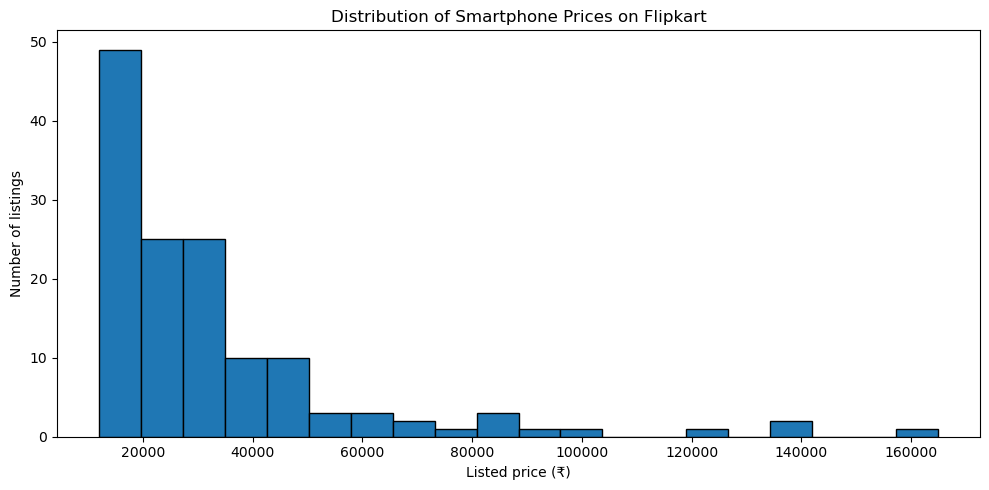

In [19]:
plt.figure(figsize=(10, 5))
plt.hist(clean_df["Price"].dropna(), bins=20, edgecolor="black")
plt.title("Distribution of Smartphone Prices on Flipkart")
plt.xlabel("Listed price (₹)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.show()

### 9.2 Most frequently listed brands

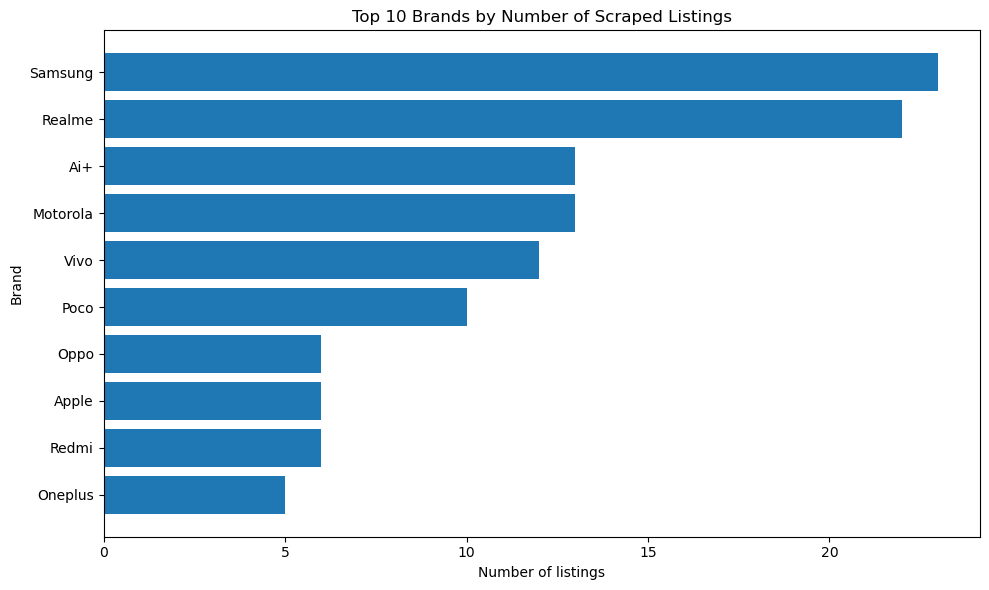

In [20]:
brand_counts = clean_df["Brand"].value_counts().head(10).sort_values()
plt.figure(figsize=(10, 6))
plt.barh(brand_counts.index.astype(str), brand_counts.values)
plt.title("Top 10 Brands by Number of Scraped Listings")
plt.xlabel("Number of listings")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

### 9.3 Average price by brand (brands with at least two listings)

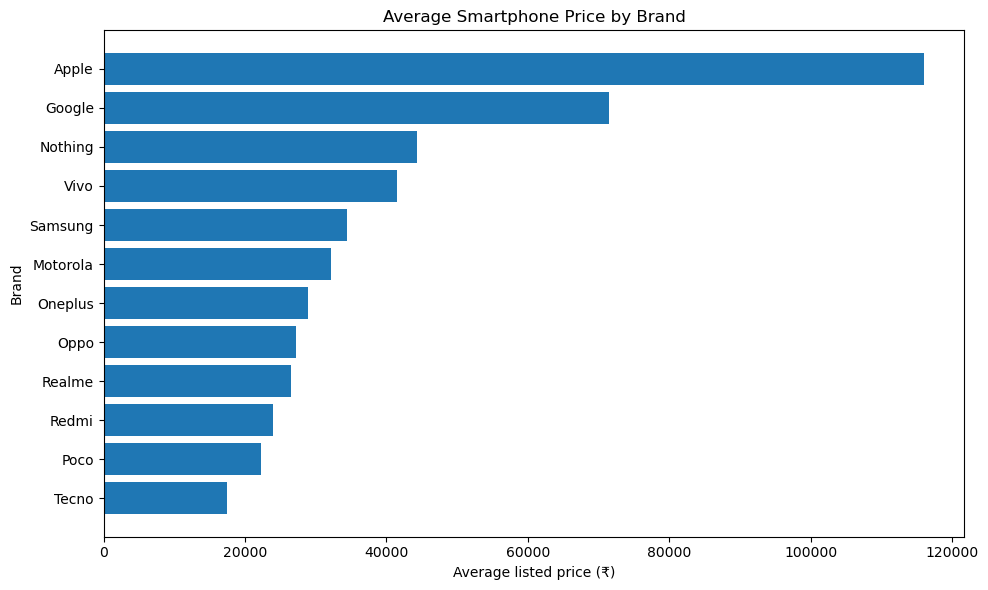

In [21]:
brands_for_price = clean_df["Brand"].value_counts()
brands_for_price = brands_for_price[brands_for_price >= 2].index
average_price_by_brand = clean_df[clean_df["Brand"].isin(brands_for_price)].groupby("Brand")["Price"].mean().sort_values().tail(12)

plt.figure(figsize=(10, 6))
plt.barh(average_price_by_brand.index.astype(str), average_price_by_brand.values)
plt.title("Average Smartphone Price by Brand")
plt.xlabel("Average listed price (₹)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

### 9.4 Price-band count

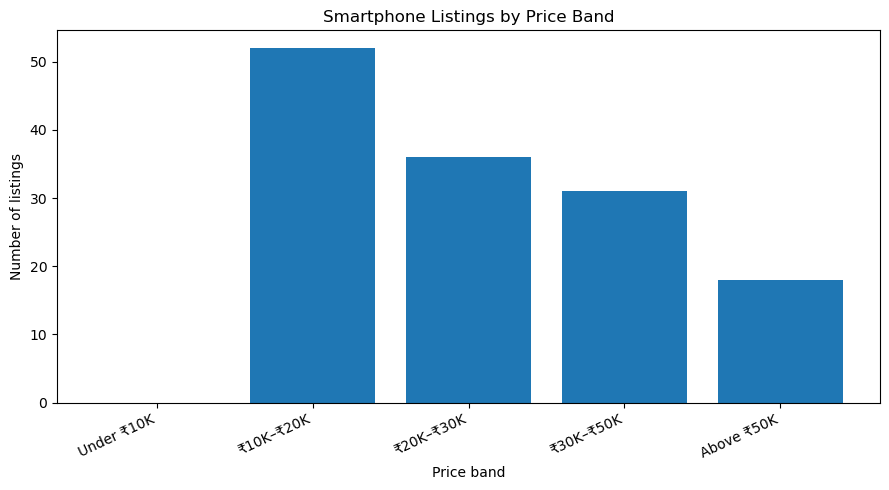

In [22]:
band_counts = clean_df["Price_Band"].value_counts().sort_index()
plt.figure(figsize=(9, 5))
plt.bar(band_counts.index.astype(str), band_counts.values)
plt.title("Smartphone Listings by Price Band")
plt.xlabel("Price band")
plt.ylabel("Number of listings")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 9.5 Price versus RAM and storage

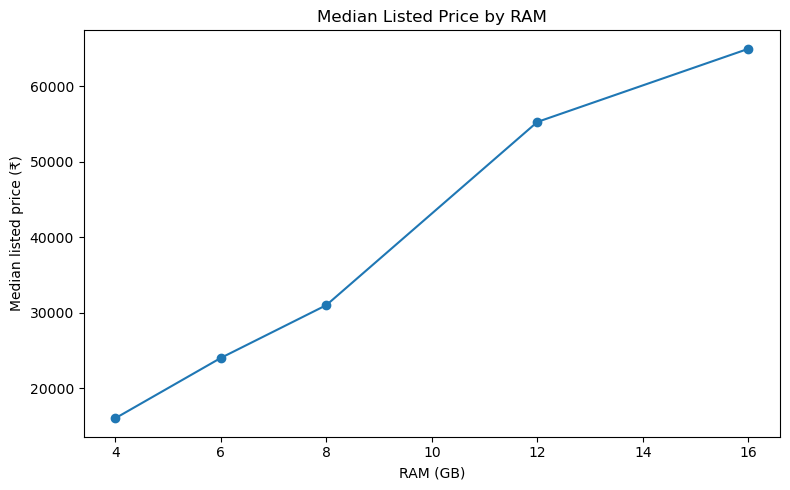

In [23]:
ram_data = clean_df.dropna(subset=["RAM_GB", "Price"])
if not ram_data.empty:
    ram_price = ram_data.groupby("RAM_GB")["Price"].median().sort_index()
    plt.figure(figsize=(8, 5))
    plt.plot(ram_price.index.astype(float), ram_price.values, marker="o")
    plt.title("Median Listed Price by RAM")
    plt.xlabel("RAM (GB)")
    plt.ylabel("Median listed price (₹)")
    plt.tight_layout()
    plt.show()
else:
    print("RAM values were not extracted; check the specification selectors.")

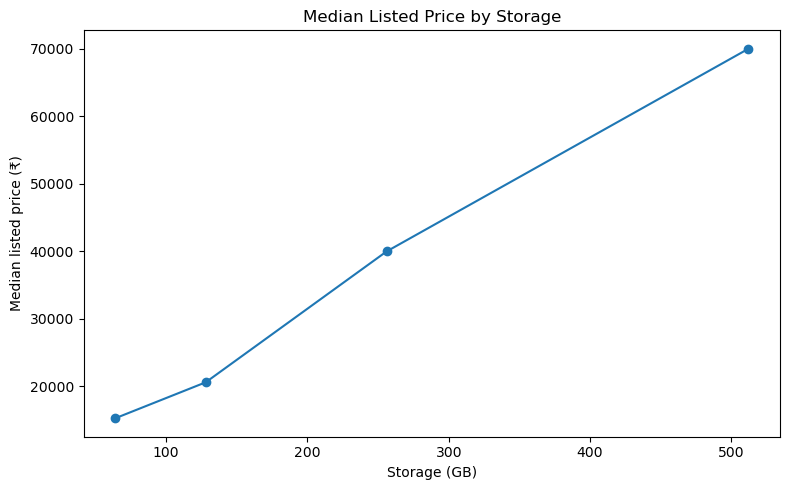

In [24]:
storage_data = clean_df.dropna(subset=["Storage_GB", "Price"])
if not storage_data.empty:
    storage_price = storage_data.groupby("Storage_GB")["Price"].median().sort_index()
    plt.figure(figsize=(8, 5))
    plt.plot(storage_price.index.astype(float), storage_price.values, marker="o")
    plt.title("Median Listed Price by Storage")
    plt.xlabel("Storage (GB)")
    plt.ylabel("Median listed price (₹)")
    plt.tight_layout()
    plt.show()
else:
    print("Storage values were not extracted; check the specification selectors.")

### 9.6 Battery capacity versus price

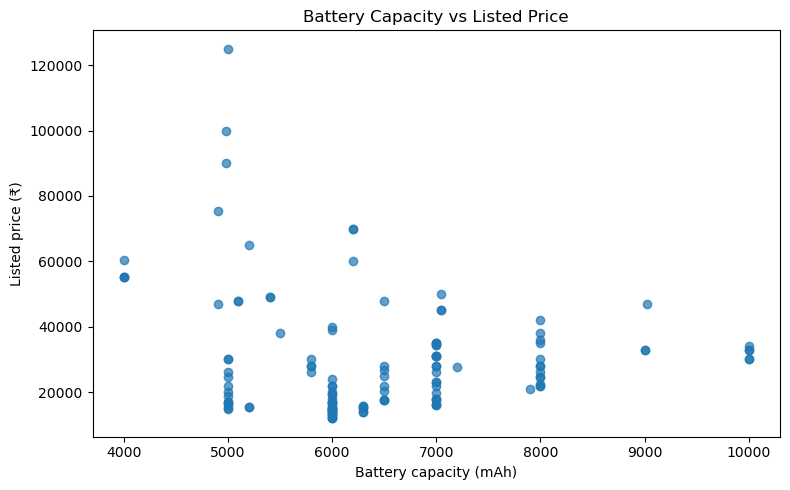

In [25]:
battery_data = clean_df.dropna(subset=["Battery_mAh", "Price"])
if not battery_data.empty:
    plt.figure(figsize=(8, 5))
    plt.scatter(battery_data["Battery_mAh"], battery_data["Price"], alpha=0.7)
    plt.title("Battery Capacity vs Listed Price")
    plt.xlabel("Battery capacity (mAh)")
    plt.ylabel("Listed price (₹)")
    plt.tight_layout()
    plt.show()
else:
    print("Battery values were not extracted; check the specification selectors.")

### 9.7 Review-count coverage

Ratings have been removed as requested. Review counts are retained as a separate field where available; they should not be interpreted as sales volume.


In [26]:
if clean_df["Reviews"].notna().any():
    print("Listings with review-count data:", int(clean_df["Reviews"].notna().sum()))
    print("Median review count:", clean_df["Reviews"].median())
else:
    print("Review-count values were not extracted reliably from the listing HTML.")


Listings with review-count data: 134
Median review count: 4134.0


## 10. Final validation and export

In [27]:
print("Final dataset shape:", clean_df.shape)
print("Final columns:", clean_df.columns.tolist())
print("Missing values:")
print(clean_df.isna().sum())
print("\nSample:")
clean_df.head(10)

Final dataset shape: (137, 13)
Final columns: ['Brand', 'Model', 'Price', 'Color', 'RAM_GB', 'Storage_GB', 'Battery_mAh', 'Display_cm', 'Reviews', 'Price_Band', 'Has_RAM_Data', 'Has_Storage_Data', 'Has_Battery_Data']
Missing values:
Brand               0
Model               0
Price               0
Color               3
RAM_GB              6
Storage_GB          0
Battery_mAh         6
Display_cm          0
Reviews             3
Price_Band          0
Has_RAM_Data        0
Has_Storage_Data    0
Has_Battery_Data    0
dtype: int64

Sample:


,Brand,Model,Price,Color,RAM_GB,Storage_GB,Battery_mAh,Display_cm,Reviews,Price_Band,Has_RAM_Data,Has_Storage_Data,Has_Battery_Data
0,Mivi,"One 5G (Green, 128 GB)",13999,Green,6,128,6000,17.14,<NA>,₹10K–₹20K,True,True,True
1,Samsung,"Galaxy S25 5G Snapdragon (Silver Shadow, 128 GB)",55299,Silver Shadow,12,128,4000,15.75,6830,Above ₹50K,True,True,True
2,Hmd,"Vibe2Pro 5G with Sarvam AI (Silver Mist, 128 GB)",16999,Silver Mist,8,128,6000,17.22,<NA>,₹10K–₹20K,True,True,True
3,Apple,"iPhone 17 (Black, 256 GB)",86999,Black,<NA>,256,<NA>,16.00,28706,Above ₹50K,False,True,False
4,Oppo,"K14 Plus 5G (Solar Orange, 128 GB)",29999,Solar Orange,6,128,8000,17.22,166,₹20K–₹30K,True,True,True
5,Mivi,"One 5G (Green, 128 GB)",14999,Green,8,128,6000,17.14,<NA>,₹10K–₹20K,True,True,True
6,Vivo,"T5x 5G (Cosmic Green, 128 GB)",27749,Cosmic Green,6,128,7200,17.17,22608,₹20K–₹30K,True,True,True
7,Samsung,"Galaxy A36 5G (Awesome Lavender, 128 GB)",25999,Awesome Lavender,8,128,5000,17.02,6250,₹20K–₹30K,True,True,True
8,Google,"Pixel 10a (Fog, 256 GB)",47999,Fog,8,256,5100,16.00,3244,₹30K–₹50K,True,True,True
9,Ai+,"Nova 2 Neo 5G (Blue, 128 GB)",14499,Blue,4,128,6000,17.13,2452,₹10K–₹20K,True,True,True


In [29]:
clean_df.to_csv("flipkart_smartphone_analysis_dataset.csv", index=False, encoding="utf-8-sig")
print("Saved final analysis dataset: flipkart_smartphone_analysis_dataset.csv")

Saved final analysis dataset: flipkart_smartphone_analysis_dataset.csv
